# Módulo 3: Planificación de Rutas Clásica con Algoritmo A*
### Marswalk 3D — NASA Space Apps Challenge

---

## 1. Grafo Topográfico 2.5D Ponderado Fisiológicamente
En lugar de tratar el terreno como una malla plana, construimos un **grafo dirigido** donde cada celda del DEM se conecta con sus 8 vecinos inmediatos.

El costo de cada arista $(u, v)$ no es la distancia euclidiana, sino el **gasto metabólico real en litros de oxígeno ($O_2$)**, incorporando penalización cuadrática estricta en pendientes superiores a $25^\circ$.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for candidate in [Path("."), Path(".."), Path("Optimal_Route"), Path("../Optimal_Route")]:
    resolved = candidate.resolve()
    if (resolved / "src" / "dem_pipeline.py").is_file():
        repo_root = resolved
        break
else:
    repo_root = Path("..").resolve()

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.dem_pipeline import DEMPipeline
from src.physiology import PhysiologicalModel
from src.astar import AStarPlanner

data_dir = repo_root / "data" / "jezero_test"
dem_pipe = DEMPipeline(data_dir)
physio = PhysiologicalModel(data_dir / "config_fisio.json")

# Instanciar planificador A* con rejilla de búsqueda 160×160
astar = AStarPlanner(dem_pipe, physio, grid_n=160)
print(f"Grafo de navegación A* inicializado: {astar.grid_n}×{astar.grid_n} ({astar.grid_n**2} nodos)")


Grafo de navegación A* inicializado: 160×160 (25600 nodos)


## 2. Formulación Matemática de $A^*$ y Heurística Admisible

El algoritmo $A^*$ explora el grafo expandiendo nodos con la función de evaluación:
$$f(n) = g(n) + h(n)$$

- $g(n)$: Costo exacto acumulado de $O_2$ desde el nodo inicial hasta el nodo $n$.
- $h(n)$: Heurística admisible que estima el costo restante hacia la meta.

### Demostración de Admisibilidad:
Para garantizar optimalidad ($A^*$ nunca sobreestima el costo real), definimos:
$$h(n) = \left( \frac{\|\mathbf{p}_{\text{meta}} - \mathbf{p}_n\|_2}{v_{\text{walk}}} \right) \cdot \dot{V}_{\text{base}} \cdot 0.85$$

Dado que la distancia euclidiana en línea recta en el plano horizontal es estrictamente menor o igual a la distancia geodésica 3D sobre cualquier relieve ($\|\Delta \mathbf{p}\|_2 \leq d_{\text{real}}$), y la tasa metabólica real en cualquier terreno cumple $\dot{V}_{\text{real}} \geq 0.85 \dot{V}_{\text{base}}$, se cumple rigurosamente:
$$h(n) \leq h^*(n) \quad \forall n$$


In [2]:
# Definir puntos de Inicio (Aterrizaje en Jezero) y Destino (Delta sedimentario)
start_point = (-4500.0, 2800.0)
goal_point  = (2200.0, -1800.0)

print(f"Calculando trayectoria A* desde {start_point} hasta {goal_point}...")
route_astar = astar.plan_route(start_point, goal_point)

m = route_astar["metrics"]
print("--- Métricas de Ruta A* ---")
print(f"Distancia Total:       {m['distance_m']/1000:.2f} km")
print(f"Oxígeno Consumido:     {m['oxygen_l']:.1f} Litros")
print(f"Pendiente Máxima:      {m['max_slope_deg']:.1f}°")
print(f"Varianza de Pendiente: {m['slope_variance']:.2f}")
print(f"Puntaje de Riesgo:     {m['risk_score']:.2f} / 1.00")


Calculando trayectoria A* desde (-4500.0, 2800.0) hasta (2200.0, -1800.0)...
--- Métricas de Ruta A* ---
Distancia Total:       8.64 km
Oxígeno Consumido:     91.0 Litros
Pendiente Máxima:      7.2°
Varianza de Pendiente: 3.35
Puntaje de Riesgo:     0.29 / 1.00


## 3. Visualización de la Ruta en Mapa de Calor y Perfil 2D


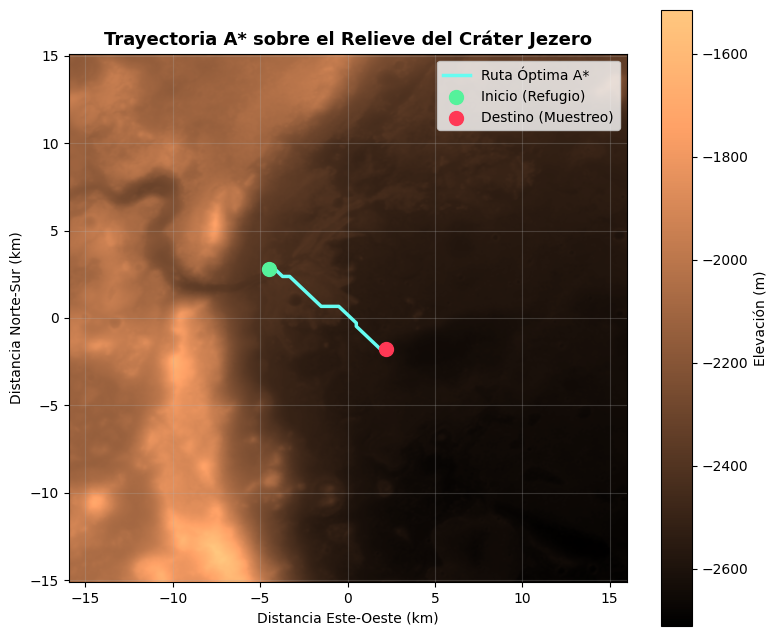

In [3]:
path_arr = np.array(route_astar["path_m"])

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(
    dem_pipe.dem,
    cmap="copper",
    extent=[-dem_pipe.half_w/1000, dem_pipe.half_w/1000, -dem_pipe.half_d/1000, dem_pipe.half_d/1000]
)

# Trazo de la ruta A* (en color cian como en el HUD de la web)
ax.plot(path_arr[:, 0] / 1000, path_arr[:, 1] / 1000, color="#66fcf1", lw=2.5, label="Ruta Óptima A*")
ax.scatter([start_point[0]/1000], [start_point[1]/1000], color="#55f29b", s=100, zorder=5, label="Inicio (Refugio)")
ax.scatter([goal_point[0]/1000], [goal_point[1]/1000], color="#ff3855", s=100, zorder=5, label="Destino (Muestreo)")

ax.set_title("Trayectoria A* sobre el Relieve del Cráter Jezero", fontsize=13, fontweight="bold")
ax.set_xlabel("Distancia Este-Oeste (km)")
ax.set_ylabel("Distancia Norte-Sur (km)")
ax.grid(True, alpha=0.25)
ax.legend(loc="upper right")
fig.colorbar(im, label="Elevación (m)")
plt.show()


## 4. Perfil Topográfico 2D (Corte Transversal Longitudinal)


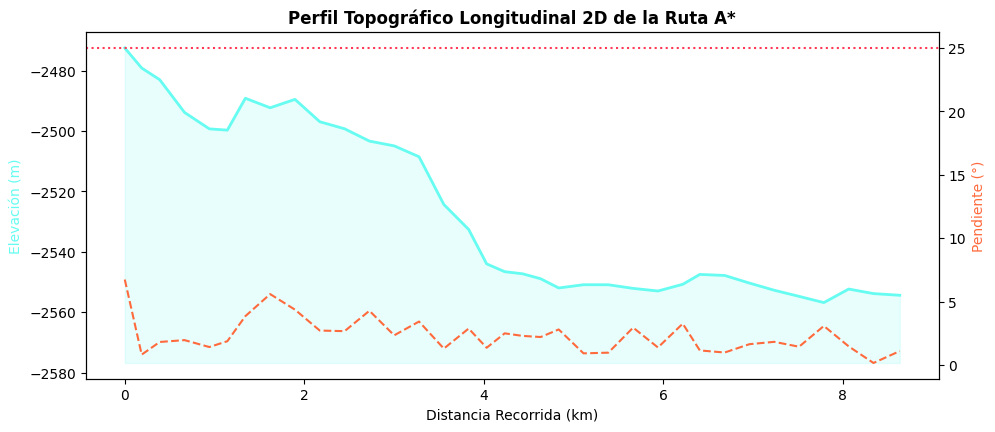

In [4]:
# Extraer distancias acumuladas, elevaciones y pendientes a lo largo de la ruta
dists = [0.0]
elevs = [dem_pipe.sample_elevation_m(path_arr[0, 0], path_arr[0, 1])]
slopes = [dem_pipe.sample_slope_deg(path_arr[0, 0], path_arr[0, 1])]

for i in range(1, len(path_arr)):
    d = np.hypot(path_arr[i, 0] - path_arr[i-1, 0], path_arr[i, 1] - path_arr[i-1, 1])
    dists.append(dists[-1] + d)
    elevs.append(dem_pipe.sample_elevation_m(path_arr[i, 0], path_arr[i, 1]))
    slopes.append(dem_pipe.sample_slope_deg(path_arr[i, 0], path_arr[i, 1]))

dists_km = np.array(dists) / 1000.0

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(dists_km, elevs, color="#66fcf1", lw=2, label="Elevación Real (m)")
ax1.fill_between(dists_km, elevs, min(elevs) - 20, color="#66fcf1", alpha=0.15)
ax1.set_xlabel("Distancia Recorrida (km)")
ax1.set_ylabel("Elevación (m)", color="#66fcf1")

ax2 = ax1.twinx()
ax2.plot(dists_km, slopes, color="#ff6a3d", lw=1.5, ls="--", label="Pendiente (°)")
ax2.axhline(25.0, color="#ff3855", ls=":", label="Límite Seguro (25°)")
ax2.set_ylabel("Pendiente (°)", color="#ff6a3d")

plt.title("Perfil Topográfico Longitudinal 2D de la Ruta A*", fontweight="bold")
plt.show()
